# Fase 1 — Caracterização do corpus FakeRecogna

**Detecção de notícias falsas em português e robustez frente à IA generativa**  
Alice Vitória Cordeiro França — IFPR Campus Paranaguá  
Tecnologia em Análise e Desenvolvimento de Sistemas

---

### O que este notebook faz

Carrega o corpus, resolve os nomes reais das colunas, unifica os campos textuais em uma única coluna de análise e caracteriza a base em três dimensões: balanceamento entre classes, completude de cada campo e distribuição do comprimento dos textos. A completude por campo é o que expõe o risco de vazamento do subtítulo, discutido na Seção 3 do artigo: um campo presente em uma classe e ausente na outra permite ao classificador acertar sem ler o conteúdo.

### Entradas

- `fakerecogna_bruto.csv`

### Saídas de dados

- `dados/corpus_base.csv`
- `dados/corpus_preparado.csv`
- `dados/metricas_corpus.csv`
- `dados/vazamento_titulo.csv`
- `dados/duplicatas.csv`

### Figuras geradas para o artigo

- `figuras/fig_corpus_balanceamento.png` — distribuição das 11.902 notícias entre as duas classes
- `figuras/fig_corpus_completude.png` — percentual de preenchimento de cada campo, por classe
- `figuras/fig_vazamento_titulo.png` — marcas de veredito no título, por classe
- `figuras/fig_duplicatas.png` — similaridade de cada registro com o mais parecido
- `figuras/fig_corpus_tamanho.png` — distribuição do número de palavras por classe

Todas as figuras saem deste notebook, em PNG de 400 dpi e 15 cm de largura, prontas para entrar no artigo em escala 1:1. O padrão visual está no módulo `estilo_sbc.py`, gravado no Drive pela célula 2 e idêntico em todas as fases.

## 1. Ambiente

In [1]:
# Monta o Google Drive e fixa a estrutura de pastas do projeto.
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

BASE    = Path('/content/drive/MyDrive/TCC')
DADOS   = BASE / 'dados'
FIGURAS = BASE / 'figuras'
MODELOS = BASE / 'modelos'
for pasta in (DADOS, FIGURAS, MODELOS):
    pasta.mkdir(parents=True, exist_ok=True)

print('projeto :', BASE)
print('dados   :', DADOS)
print('figuras :', FIGURAS)
print('modelos :', MODELOS)


Mounted at /content/drive
projeto : /content/drive/MyDrive/TCC
dados   : /content/drive/MyDrive/TCC/dados
figuras : /content/drive/MyDrive/TCC/figuras
modelos : /content/drive/MyDrive/TCC/modelos


## 2. Padrão visual das figuras

A célula abaixo grava o módulo `estilo_sbc.py` e a seguinte o importa. O cabeçalho do módulo justifica cada decisão visual em relação ao template da SBC — largura útil, corpo tipográfico, resolução e separação de luminância para impressão em preto e branco. Por ser o mesmo módulo nas oito fases, nenhuma figura do artigo sai fora do padrão.

In [2]:
%%writefile /content/estilo_sbc.py
# -*- coding: utf-8 -*-
"""
estilo_sbc - padrao visual unico para todas as figuras do artigo.

Cada decisao abaixo responde a uma exigencia concreta do template da SBC.

1. Largura de exatamente 15 cm, garantida no arquivo final. E a area util de
   texto do template em A4 com margens laterais de 3 cm. Nao basta pedir
   `figsize`: o `bbox_inches='tight'` do matplotlib recorta ou expande a
   figura conforme o tamanho dos rotulos, e o PNG sai com largura
   imprevisivel - entre 12 e 17 cm, nos testes. A funcao `salvar` normaliza:
   mede o resultado, completa com branco quando falta e reduz quando sobra,
   e grava a resolucao nos metadados do PNG. O Word e o LaTeX passam a
   inserir a imagem no tamanho fisico certo sem ajuste manual, e so por isso
   a afirmacao de escala 1:1 se sustenta.
2. Tipografia entre 9 e 10,5 pt no grafico. Em escala 1:1 isso fica
   proximo do corpo do texto (Times 12 pt): legivel, sem competir com ele.
3. 400 dpi em PNG. O minimo usual para impressao e 300 dpi.
4. Paleta azul / vermelhao / ambar, derivada de Okabe-Ito, que e a
   referencia de cores seguras para daltonismo em figuras cientificas. O par
   azul-laranja e o mais comum na literatura justamente por ser o que
   sobrevive as tres formas de daltonismo. As luminancias valem 0,27, 0,47 e
   0,71: o template preve avaliacao impressa, eventualmente em preto e
   branco, e cores de luminancia proxima colapsam no mesmo cinza.
5. Escala tipografica fechada, de T_PEQUENO a T_DESTAQUE. Toda figura usa
   esses cinco tamanhos e nenhum outro: tamanhos escolhidos caso a caso
   fazem o conjunto parecer montado por pessoas diferentes.
6. Nenhum texto dentro da area de dados. Rotulo de serie vai para a legenda
   abaixo do eixo, valor de referencia vai para a linha de apoio do titulo.
   Texto sobre os dados colide assim que os dados mudam - e o que fez a
   primeira versao destas figuras ficar ilegivel com o corpus real.
7. Moldura aberta (sem as linhas superior e direita), grade apenas no eixo
   de valores e rotulo numerico em cada elemento: o leitor le o valor em
   vez de estima-lo pela altura da barra.
8. Eixo de valores sempre a partir de zero nos graficos de barra. Quando a
   diferenca entre as series e pequena demais para aparecer, troca-se o
   grafico de barras por um dot plot - truncar o eixo exageraria a
   diferenca e seria enganoso.

Uso:
    from estilo_sbc import *
    destino('/content/drive/MyDrive/TCC/figuras')
    fig, ax = plt.subplots(figsize=(LARGURA, 7*CM))
    ...
    salvar(fig, 'fig_exemplo')
"""

import io
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, MaxNLocator
from PIL import Image

# ----------------------------------------------------------------- paleta
# Azul, vermelhao e ambar, da familia Okabe-Ito. O azul foi escurecido em
# relacao ao original para abrir distancia de luminancia dos outros dois e
# alcancar contraste de texto sobre branco.
AZUL    = '#1B4F72'   # serie primaria   (Regressao Logistica) - luminancia 0,27
LARANJA = '#D55E00'   # serie secundaria (Random Forest)       - luminancia 0,47
AMBAR   = '#E8B04B'   # serie terciaria  (BERTimbau)           - luminancia 0,71
VERDE   = '#117733'   # acento, so quando existe uma quarta serie
TEXTO   = '#1A1A1A'
SUAVE   = '#5F6B7A'
GRADE   = '#E4E7EA'
NEUTRO  = '#C3C9D0'

PALETA  = [AZUL, LARANJA, AMBAR, VERDE]

# Variantes escurecidas para TEXTO. A luminancia que separa as cores na
# impressao em cinza e justamente o que derruba o contraste delas sobre o
# branco: o vermelhao alcanca 3,9:1 e o ambar 1,9:1, abaixo do minimo de
# 4,5:1 que a WCAG pede para texto deste corpo. Preencher formas com a cor da
# serie e escrever com a variante escura resolve os dois lados.
AZUL_TEXTO    = AZUL       # 8,8:1
LARANJA_TEXTO = '#A64A00'  # 5,8:1
AMBAR_TEXTO   = '#8A6410'  # 5,1:1
VERDE_TEXTO   = '#0E5C28'

_LEGIVEL = {AZUL: AZUL_TEXTO, LARANJA: LARANJA_TEXTO,
            AMBAR: AMBAR_TEXTO, VERDE: VERDE_TEXTO}

# ------------------------------------------------------------ tipografia
# Escala fechada. Nenhuma figura inventa um tamanho fora destes cinco.
T_PEQUENO  = 8.0    # nota de rodape dentro da figura, anotacao secundaria
T_CORPO    = 9.0    # eixos, legenda, linha de apoio do titulo
T_ROTULO   = 9.5    # valor escrito sobre barra ou ponto
T_TITULO   = 10.5   # titulo da figura e de cada painel
T_DESTAQUE = 13.0   # numero isolado em painel de sintese


def legivel(cor):
    """Variante da cor com contraste suficiente para texto sobre branco."""
    return _LEGIVEL.get(cor, cor)


CORES_MODELO = {
    'Regressao Logistica': AZUL,
    'Regressão Logística': AZUL,
    'Random Forest': LARANJA,
    'BERTimbau': AMBAR,
}
CORES_CLASSE = {'Verdadeira': AZUL, 'Falsa': LARANJA}

# Comeca num cinza muito claro, nao em branco puro: com branco as celulas
# de valor zero somem e a matriz perde a forma de matriz.
MAPA_FRIO = LinearSegmentedColormap.from_list('sbc_frio', ['#F1F4F5', AZUL])
MAPA_DIV  = LinearSegmentedColormap.from_list('sbc_div', [AZUL, '#FFFFFF', LARANJA])

# ----------------------------------------------------------------- medidas
CM = 1 / 2.54
LARGURA = 15 * CM          # largura total da area de texto do template
LARGURA_MEIA = 7.2 * CM    # duas figuras lado a lado

# ----------------------------------------------------------------- tipografia
# DejaVu Sans vem instalada no Colab e cobre toda a acentuacao do portugues,
# mas tem apenas dois pesos: normal e negrito. Pedir 'semibold' faz o
# matplotlib emitir aviso e cair no negrito de qualquer forma, por isso os
# pesos aqui sao sempre 'normal' ou 'bold'. Se uma familia com mais pesos
# estiver instalada no ambiente, ela e usada - sem exigir instalacao nenhuma.
_instaladas = {f.name for f in mpl.font_manager.fontManager.ttflist}
FAMILIA = next((f for f in ('Inter', 'Source Sans 3', 'Lato', 'Open Sans',
                            'Liberation Sans', 'DejaVu Sans')
                if f in _instaladas), 'sans-serif')

# ----------------------------------------------------------------- rcParams
mpl.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 400,
    'savefig.bbox': 'tight',
    'savefig.facecolor': 'white',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',

    'font.family': FAMILIA,
    'font.size': T_CORPO,
    'axes.titlesize': T_TITULO,
    'axes.titleweight': 'bold',
    'axes.titlepad': 12,
    'axes.labelsize': T_CORPO,
    'axes.labelcolor': TEXTO,
    'axes.labelpad': 10,
    'xtick.labelsize': T_CORPO,
    'ytick.labelsize': T_CORPO,
    'legend.fontsize': T_CORPO,

    'text.color': TEXTO,
    'axes.edgecolor': '#B9BDC2',
    'axes.linewidth': 0.8,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.spines.left': False,

    'xtick.color': SUAVE,
    'ytick.color': SUAVE,
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.major.size': 0,
    'ytick.major.size': 0,
    'xtick.major.pad': 5,
    'ytick.major.pad': 5,

    'grid.color': GRADE,
    'grid.linewidth': 0.8,
    'axes.grid': False,

    'legend.frameon': False,
    'legend.handlelength': 1.2,
    'legend.handleheight': 1.2,
    'legend.columnspacing': 2.2,
    'legend.borderpad': 0.1,
    'legend.labelspacing': 0.6,

    'axes.prop_cycle': mpl.cycler(color=PALETA),
    'lines.linewidth': 2.0,
    'lines.markersize': 6,
    'patch.linewidth': 0,
})

# ----------------------------------------------------------------- destino
_destino = Path('.')


def destino(pasta):
    """Define a pasta onde salvar() grava as figuras."""
    global _destino
    _destino = Path(pasta)
    _destino.mkdir(parents=True, exist_ok=True)
    return _destino


def salvar(fig, nome, largura_cm=15.0, dpi=400):
    """Grava a figura em PNG com largura fisica exata e dpi nos metadados.

    O matplotlib com bbox_inches='tight' devolve larguras diferentes a cada
    figura, conforme o tamanho dos rotulos. Aqui o resultado e normalizado
    para `largura_cm`: se ficou estreito, completa-se com branco, o que
    preserva o corpo das letras; se ficou largo, reduz-se a imagem inteira,
    e a reducao aplicada e informada na saida. Passe largura_cm=None para
    gravar sem normalizar.
    """
    caminho = _destino / (nome + '.png')
    if largura_cm is None:
        fig.savefig(caminho, dpi=dpi, bbox_inches='tight', facecolor='white')
        print('[figura]', caminho.name, '(sem normalizacao)')
        return caminho

    alvo = int(round(largura_cm / 2.54 * dpi))
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=dpi, bbox_inches='tight',
                facecolor='white')
    buf.seek(0)
    im = Image.open(buf).convert('RGB')
    nota = ''
    if im.width > alvo:
        fator = alvo / im.width
        im = im.resize((alvo, max(1, int(round(im.height * fator)))),
                       Image.LANCZOS)
        nota = '  (reduzida {:.1%})'.format(1 - fator)
    elif im.width < alvo:
        tela = Image.new('RGB', (alvo, im.height), 'white')
        tela.paste(im, ((alvo - im.width) // 2, 0))
        im = tela
        nota = '  (margem branca completada)'
    im.save(caminho, dpi=(dpi, dpi))
    print('[figura] {:<30} {:.1f} x {:.1f} cm{}'
          .format(caminho.name, largura_cm, im.height / dpi * 2.54, nota))
    return caminho


# ----------------------------------------------------------------- helpers
def br(texto):
    """Converte um numero ja formatado para a convencao brasileira.

    Troca o separador decimal por virgula e o de milhar por ponto. Um artigo
    em portugues com "97.40%" no grafico e "97,40%" no texto nao passa pela
    revisao, entao a conversao fica embutida nos helpers de rotulo e nos
    formatadores de eixo - nao depende de lembrar caso a caso.
    """
    return str(texto).replace(',', '\u0000').replace('.', ',').replace('\u0000', '.')


def pct(valor, dec=1):
    """Percentual na convencao brasileira: pct(0.974, 2) -> '97,40%'."""
    return br(('{:.' + str(dec) + 'f}').format(100 * valor)) + '%'


def mil(valor, dec=0):
    """Inteiro com separador de milhar: mil(11902) -> '11.902'."""
    return br(('{:,.' + str(dec) + 'f}').format(valor))


def grade_y(ax, atras=True):
    """Grade horizontal apenas (para barras verticais e linhas)."""
    ax.grid(axis='y', color=GRADE, linewidth=0.8)
    ax.grid(axis='x', visible=False)
    ax.set_axisbelow(atras)
    return ax


def grade_x(ax, atras=True):
    """Grade vertical apenas (para barras horizontais)."""
    ax.grid(axis='x', color=GRADE, linewidth=0.8)
    ax.grid(axis='y', visible=False)
    ax.set_axisbelow(atras)
    return ax


def sem_grade(ax):
    ax.grid(False)
    for lado in ('top', 'right', 'left', 'bottom'):
        ax.spines[lado].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    return ax


def eixo_percentual(ax, eixo='y', decimais=0):
    f = FuncFormatter(lambda v, _: pct(v, decimais))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def eixo_decimal(ax, eixo='y', decimais=2):
    """Eixo numerico comum, tambem com virgula decimal."""
    f = FuncFormatter(
        lambda v, _: br(('{:,.' + str(decimais) + 'f}').format(v)))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def escala_percentual(ax, maximo=1.0, folga_topo=0.20, passo=0.2, decimais=0):
    """Eixo percentual com folga no topo sem inventar marcas acima do maximo.

    Abrir espaco apenas com set_ylim faz o matplotlib desenhar marcas de 110%
    ou 120% num eixo de acuracia, o que nao existe. Aqui a folga e so espaco
    em branco: as marcas param no maximo real.
    """
    import numpy as _np
    ax.set_ylim(0, maximo * (1 + folga_topo))
    ax.set_yticks(_np.round(_np.arange(0, maximo + 1e-9, passo), 10))
    eixo_percentual(ax, 'y', decimais)
    return ax


def eixo_milhar(ax, eixo='y'):
    f = FuncFormatter(lambda v, _: mil(v))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def rotular(ax, barras, fmt='{:.1%}', dy=5, tam=T_ROTULO, peso='bold', cor=None):
    """Escreve o valor acima de cada barra vertical."""
    for b in barras:
        v = b.get_height()
        ax.annotate(br(fmt.format(v)),
                    xy=(b.get_x() + b.get_width() / 2, v),
                    xytext=(0, dy), textcoords='offset points',
                    ha='center', va='bottom',
                    fontsize=tam, fontweight=peso,
                    color=cor or TEXTO)
    return ax


def rotular_h(ax, barras, fmt='{:.1%}', dx=6, tam=T_ROTULO, peso='bold', cor=None):
    """Escreve o valor a direita de cada barra horizontal."""
    for b in barras:
        v = b.get_width()
        ax.annotate(br(fmt.format(v)),
                    xy=(v, b.get_y() + b.get_height() / 2),
                    xytext=(dx, 0), textcoords='offset points',
                    ha='left', va='center',
                    fontsize=tam, fontweight=peso,
                    color=cor or TEXTO)
    return ax


def encolher_para_caber(ax, textos, largura_dados, tamanho, minimo=6.5,
                        passo=0.2):
    """Reduz o corpo de um conjunto de textos ate o mais largo caber.

    Mede a largura real de cada texto na figura renderizada, em vez de
    confiar numa estimativa por numero de caracteres - a largura depende da
    fonte, do peso e de quais letras sao. O mesmo tamanho e aplicado a todos
    os textos do conjunto: encolher so o que transborda deixaria um rotulo
    menor que os vizinhos, o que aparece mais do que o problema original.
    """
    fig = ax.figure
    fig.canvas.draw()
    renderizador = fig.canvas.get_renderer()
    base = ax.transData.transform((0, 0))[0]
    limite = ax.transData.transform((largura_dados, 0))[0] - base
    while tamanho > minimo:
        maior = max(t.get_window_extent(renderer=renderizador).width
                    for t in textos)
        if maior <= limite:
            break
        tamanho -= passo
        for t in textos:
            t.set_fontsize(tamanho)
    return tamanho


def legenda_abaixo(ax, ncols=2, afastamento=None, **kwargs):
    """Legenda centralizada abaixo do eixo, fora da area de dados.

    Posicao unica para todas as figuras do artigo, por dois motivos. O
    primeiro e consistencia: legenda ora dentro, ora fora, faz o conjunto
    parecer montado aos pedacos. O segundo e que legenda dentro do grafico
    so fica livre por acaso - ela nao sabe onde estao os dados, e basta o
    corpus mudar para ela cair em cima deles.
    """
    # O afastamento e calculado em pontos e so depois convertido para
    # fracao do eixo. Usar uma fracao fixa afasta a legenda de forma
    # diferente em cada figura - num grafico de barras horizontais, alto, a
    # mesma fracao joga a legenda muito mais para baixo do que num grafico
    # baixo, e em alguns casos ela sobe por cima do rotulo do eixo.
    altura_pt = (ax.get_position().height * ax.figure.get_figheight() * 72) or 1
    if afastamento is None:
        afastamento = -(44 if ax.get_xlabel() else 24) / altura_pt
    return ax.legend(loc='upper center', ncols=ncols,
                     bbox_to_anchor=(0.5, afastamento),
                     fontsize=T_CORPO, **kwargs)


def legenda_manual(ax, itens, ncols=None, **kwargs):
    """Legenda abaixo do eixo montada a partir de (rotulo, cor).

    Para graficos cujos artistas nao carregam rotulo - area empilhada,
    histograma desenhado em duas passagens, barras coloridas uma a uma.
    """
    from matplotlib.patches import Patch
    marcas = [Patch(facecolor=cor, label=rotulo) for rotulo, cor in itens]
    return legenda_abaixo(ax, ncols=ncols or len(itens), handles=marcas,
                          **kwargs)


def titulo(ax, principal, apoio=None):
    """Titulo em duas linhas: a afirmacao e, abaixo, a leitura de apoio.

    A linha de apoio e desenhada como anotacao acima do eixo, entao o
    afastamento do titulo precisa acomoda-la - com o `pad` padrao os dois
    se sobrepoem.
    """
    linhas_apoio = apoio.count('\n') + 1 if apoio else 0
    ax.set_title(principal, loc='left',
                 pad=(25 + 12 * (linhas_apoio - 1)) if apoio else 10)
    if apoio:
        ax.annotate(apoio, xy=(0, 1), xycoords='axes fraction',
                    xytext=(0, 7), textcoords='offset points',
                    ha='left', va='bottom', fontsize=T_CORPO, color=SUAVE)
    return ax


def espacar(valores, minimo):
    """Afasta rotulos proximos demais para que nao se sobreponham.

    Devolve posicoes verticais na mesma unidade dos valores, preservando a
    ordem original. Usada quando varias series terminam em valores vizinhos:
    sem isso os rotulos se empilham e nenhum fica legivel.
    """
    import numpy as _np
    valores = _np.asarray(valores, dtype=float)
    pos = valores.copy()
    ordem = _np.argsort(valores)
    for k in range(1, len(ordem)):
        anterior, atual = ordem[k - 1], ordem[k]
        if pos[atual] - pos[anterior] < minimo:
            pos[atual] = pos[anterior] + minimo
    deslocamento = pos[ordem].mean() - valores[ordem].mean()
    return pos - deslocamento


def folga(ax, eixo='y', fator=0.14):
    """Abre espaco no topo para os rotulos nao encostarem na borda."""
    if eixo == 'y':
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi + (hi - lo) * fator)
    else:
        lo, hi = ax.get_xlim()
        ax.set_xlim(lo, hi + (hi - lo) * fator)
    return ax


def painel_confusao(ax, matriz, titulo_painel, rotulos=('Verdadeira', 'Falsa'),
                    destaque=None):
    """Matriz de confusao 2x2 com contagem e percentual por celula."""
    import numpy as np
    matriz = np.asarray(matriz, dtype=float)
    total = matriz.sum()
    ax.imshow(matriz / matriz.max(), cmap=MAPA_FRIO, vmin=0, vmax=1.15)
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            v = matriz[i, j]
            claro = (v / matriz.max()) > 0.55
            ax.text(j, i - 0.10, mil(v),
                    ha='center', va='center', fontsize=T_DESTAQUE,
                    fontweight='bold',
                    color='white' if claro else TEXTO)
            ax.text(j, i + 0.22, pct(v / total, 1),
                    ha='center', va='center', fontsize=T_PEQUENO,
                    color='#E8EEF0' if claro else SUAVE)
    ax.set_xticks([0, 1], ['Predita\n' + rotulos[0], 'Predita\n' + rotulos[1]])
    ax.set_yticks([0, 1], ['Real\n' + rotulos[0], 'Real\n' + rotulos[1]])
    ax.set_title(titulo_painel, loc='center', pad=10,
                 color=legivel(destaque) if destaque else TEXTO)
    for lado in ('top', 'right', 'left', 'bottom'):
        ax.spines[lado].set_visible(False)
    ax.tick_params(length=0)
    ax.grid(False)
    return ax


def barras_pareadas(ax, categorias, series, fmt='{:.1%}', largura_grupo=0.78,
                    rotulo=True):
    """Barras agrupadas. `series` e uma lista de (nome, valores, cor)."""
    import numpy as np
    x = np.arange(len(categorias))
    n = len(series)
    larg = largura_grupo / n
    for k, (nome, valores, cor) in enumerate(series):
        desloc = (k - (n - 1) / 2) * larg
        b = ax.bar(x + desloc, valores, larg * 0.92, label=nome, color=cor)
        if rotulo:
            rotular(ax, b, fmt=fmt, tam=T_PEQUENO)
    ax.set_xticks(x, categorias)
    grade_y(ax)
    return ax


print('estilo_sbc carregado  |  paleta', AZUL, LARANJA, AMBAR)


Writing /content/estilo_sbc.py


In [3]:
# Copia o modulo para o Drive (fica versionado junto com o projeto) e importa.
import shutil, sys
shutil.copy('/content/estilo_sbc.py', BASE / 'estilo_sbc.py')
sys.path.insert(0, '/content')

from estilo_sbc import *      # noqa: F401,F403
destino(FIGURAS)

import numpy as np
import pandas as pd


estilo_sbc carregado  |  paleta #1B4F72 #D55E00 #E8B04B


## 3. Localizadores de arquivos e colunas

In [4]:
# Os arquivos podem estar em TCC/ ou em TCC/dados/; procura nos dois.

def arquivo(*nomes):
    """Primeiro dos nomes que existir em dados/ ou na raiz."""
    tentados = []
    for nome in nomes:
        for pasta in (DADOS, BASE):
            alvo = pasta / nome
            tentados.append(str(alvo))
            if alvo.exists():
                return alvo
    raise FileNotFoundError(
        'Nenhum destes arquivos foi encontrado:\n  ' + '\n  '.join(tentados))


def existe(*nomes):
    try:
        return arquivo(*nomes)
    except FileNotFoundError:
        return None


def coluna(df, *candidatos, obrigatoria=True):
    """Resolve o nome real de uma coluna a partir de varios candidatos."""
    mapa = {c.strip().lower(): c for c in df.columns}
    for cand in candidatos:
        if cand.strip().lower() in mapa:
            return mapa[cand.strip().lower()]
    for cand in candidatos:
        chave = cand.strip().lower()
        for norm, orig in mapa.items():
            if chave in norm:
                return orig
    if obrigatoria:
        raise KeyError('Nenhuma destas colunas existe: ' + ', '.join(candidatos)
                       + '\nDisponiveis: ' + ', '.join(map(str, df.columns)))
    return None


def csvs_do_projeto():
    """Todos os CSV sob a pasta do projeto, com contagem de linhas e colunas."""
    achados = []
    for caminho in sorted(BASE.rglob('*.csv')):
        try:
            cabecalho = list(pd.read_csv(caminho, nrows=0).columns)
            with open(caminho, encoding='utf-8', errors='ignore') as fh:
                linhas = max(sum(1 for _ in fh) - 1, 0)
        except Exception as erro:
            cabecalho, linhas = ['<ilegível: {}>'.format(erro)], -1
        achados.append((caminho, linhas, cabecalho))
    return achados


def listar_csvs():
    """Inventário dos CSV da pasta do projeto."""
    achados = csvs_do_projeto()
    if not achados:
        print('nenhum CSV encontrado em', BASE)
        return
    for caminho, linhas, colunas in achados:
        print('{:<44} {:>7} linhas   {}'.format(
            str(caminho.relative_to(BASE)), linhas,
            ', '.join(map(str, colunas))[:88]))


def procurar_csv(*pistas_de_coluna, nomes=()):
    """Acha um CSV pelo nome e, falhando isso, pelas colunas."""
    if nomes:
        alvo = existe(*nomes)
        if alvo is not None:
            return alvo
    candidatos = []
    for caminho, linhas, colunas in csvs_do_projeto():
        normalizadas = {str(c).strip().lower() for c in colunas}
        if any(any(pista in c for c in normalizadas) for pista in pistas_de_coluna):
            candidatos.append((linhas, caminho))
    if candidatos:
        candidatos.sort(reverse=True)
        escolhido = candidatos[0][1]
        print('localizado pelo conteúdo:', escolhido.relative_to(BASE))
        if len(candidatos) > 1:
            print('outros compatíveis:',
                  [str(c.relative_to(BASE)) for _, c in candidatos[1:]])
        return escolhido
    print('Nenhum CSV com coluna parecida com', pistas_de_coluna, 'foi encontrado.')
    print('Nomes procurados:', nomes or '(nenhum)')
    print('\nCSVs disponíveis em', BASE, ':')
    listar_csvs()
    raise FileNotFoundError(
        'Veja o inventário acima e renomeie o arquivo certo, ou gere-o de novo.')


def modelos_disponiveis():
    """(pasta, data, convencao) de cada modelo salvo sob o projeto.

    A convencao vem de convencao_rotulo.json, gravado pela Fase 5: sem ela
    nao da para saber se o rotulo 1 do modelo significa falsa ou verdadeira.
    """
    import datetime as _dt
    import json as _json
    achados = []
    for config in sorted(BASE.rglob('config.json')):
        pasta = config.parent
        if not (pasta / 'model.safetensors').exists() \
                and not (pasta / 'pytorch_model.bin').exists():
            continue
        marca = pasta / 'convencao_rotulo.json'
        convencao = None
        if marca.exists():
            try:
                convencao = _json.loads(marca.read_text(encoding='utf-8'))
            except Exception:
                convencao = {'erro': 'json ilegivel'}
        achados.append((pasta,
                        _dt.datetime.fromtimestamp(config.stat().st_mtime),
                        convencao))
    return sorted(achados, key=lambda t: t[1], reverse=True)


def listar_modelos():
    achados = modelos_disponiveis()
    if not achados:
        print('nenhum modelo encontrado em', BASE)
        return
    for pasta, quando, convencao in achados:
        print('{:<46} {}  {}'.format(
            str(pasta.relative_to(BASE)), quando.strftime('%d/%m %H:%M'),
            'rótulo 1 = ' + convencao.get('1', '?') if convencao
            else 'SEM convenção declarada'))


def achar_modelo(convencao_exigida='Falsa'):
    """Pasta do BERTimbau ajustado que declare a convencao de rotulo pedida.

    Escolher por uma lista fixa de nomes nao distingue o modelo desta
    execucao de um modelo antigo salvo no mesmo caminho, e um modelo
    treinado sob a convencao oposta acerta menos que o acaso.
    """
    disponiveis = [t for t in modelos_disponiveis()
                   if 'checkpoint' not in t[0].name]
    if not disponiveis:
        return None

    corretos = [t for t in disponiveis
                if t[2] and t[2].get('1') == convencao_exigida]
    if corretos:
        return str(corretos[0][0])

    print('AVISO: nenhum modelo declara a convenção "rótulo 1 =',
          convencao_exigida, '". Usando o mais recente; confira a acurácia.')
    listar_modelos()
    return str(disponiveis[0][0])


_NLP = None


def motor_lema():
    """Carrega o spaCy português uma vez por sessão."""
    global _NLP
    if _NLP is None:
        import spacy
        try:
            _NLP = spacy.load('pt_core_news_sm', disable=['parser', 'ner'])
        except OSError:
            import subprocess, sys
            subprocess.run([sys.executable, '-m', 'spacy', 'download',
                            'pt_core_news_sm'], check=True)
            _NLP = spacy.load('pt_core_news_sm', disable=['parser', 'ner'])
    return _NLP


def lematizar(textos, lote=32):
    """Reduz cada texto à sequência de lemas, como o corpus foi distribuído."""
    nlp = motor_lema()
    return [' '.join(t.lemma_ for t in doc)
            for doc in nlp.pipe(list(textos), batch_size=lote)]


def taxa_de_lema(textos, limite=400):
    """Fração de tokens alfabéticos que já coincidem com o próprio lema.

    Mede o quanto um conjunto já está na forma lematizada: o corpus fica
    acima de 0,90 e o português corrente, perto de 0,60.
    """
    nlp = motor_lema()
    iguais = total = 0
    for doc in nlp.pipe(list(textos)[:limite], batch_size=32):
        for t in doc:
            if t.is_alpha and len(t.text) > 2:
                total += 1
                iguais += t.text.lower() == t.lemma_.lower()
    return iguais / total if total else float('nan')


## 4. Carga e identificação das colunas

O corpus passou por renomeações ao longo do projeto, por isso cada coluna é resolvida por uma lista de candidatos em vez de um nome fixo. A célula imprime o mapeamento efetivamente usado — vale conferir essa saída antes de seguir.

In [5]:
bruto = pd.read_csv(arquivo('fakerecogna_bruto.csv', 'FakeRecogna.csv'))
print('registros:', len(bruto), ' colunas:', list(bruto.columns), '\n')

COL = {
    'titulo':    coluna(bruto, 'titulo', 'título', 'title'),
    'subtitulo': coluna(bruto, 'subtitulo', 'subtítulo', 'sub-title', 'subtitle',
                        obrigatoria=False),
    'noticia':   coluna(bruto, 'noticia', 'notícia', 'news', 'texto', 'text',
                        'conteudo'),
    'categoria': coluna(bruto, 'categoria', 'category', obrigatoria=False),
    'url':       coluna(bruto, 'url', 'link', 'fonte', obrigatoria=False),
    'classe':    coluna(bruto, 'classe', 'class', 'label', 'rotulo'),
}
for k, v in COL.items():
    print('{:<10} -> {}'.format(k, v))


registros: 11903  colunas: ['Titulo', 'Subtitulo', 'Noticia', 'Categoria', 'Data', 'Autor', 'URL', 'Classe', 'n_palavras_noticia'] 

titulo     -> Titulo
subtitulo  -> Subtitulo
noticia    -> Noticia
categoria  -> Categoria
url        -> URL
classe     -> Classe


### Convenção de rótulo

A convenção vem da documentação oficial do corpus. O README do repositório dos autores descreve a coluna `Class` como *"label of the sample, 0 for fake news and 1 for real news"*. É essa a fonte usada aqui.

A documentação sozinha não basta, porém: o arquivo que está no Drive pode ser outra versão, ou ter sido alterado. A célula confere a convenção documentada contra a procedência de cada registro — a notícia falsa vem de agência de checagem, a verdadeira vem de veículo de imprensa — e **interrompe a execução** se as duas discordarem.

O cuidado vem de erro cometido: uma versão anterior assumia `1 = falsa` e estava invertida. Não houve exceção nenhuma, apenas uma análise inteira coerente consigo mesma e errada do começo ao fim, com o vocabulário institucional marcado como falso e as agências de checagem contadas como fonte de notícia verdadeira.

In [6]:
# Domínios de agência de checagem. A notícia falsa do corpus vem daqui.
AGENCIAS = ('boatos.org', 'aosfatos', 'e-farsas', 'checamos.afp', 'afp-brasil',
            'projetocomprova', '/comprova/', 'lupa', '/confere/',
            'fato-ou-fake', 'verifica')

# Convencao documentada pelos autores do corpus, no README do repositorio
# oficial: "Class: label of the sample, 0 for fake news and 1 for real news".
# Esta e a fonte; a deducao por procedencia abaixo vira conferencia.
MAPA_CLASSE = {0: 'Falsa', 1: 'Verdadeira'}
print('convenção documentada (README do FakeRecogna):', MAPA_CLASSE)


def de_agencia(url):
    u = str(url).lower()
    return any(p in u for p in AGENCIAS)


# Conferencia independente: a classe falsa deve concentrar as URLs de
# agencia de checagem. Se discordar da documentacao, o arquivo nao e o que
# se supoe e a execucao para — em vez de seguir com os rotulos trocados.
if COL['url'] is not None:
    proporcao = (bruto[COL['url']].map(de_agencia)
                 .groupby(bruto[COL['classe']]).mean())
    print('\nURLs de agência de checagem, por valor da coluna {}:'
          .format(COL['classe']))
    print((proporcao * 100).round(1).to_string())

    deduzido = int(proporcao.idxmax())
    if MAPA_CLASSE[deduzido] != 'Falsa':
        raise ValueError(
            'A procedência contradiz a documentação: o valor {} concentra as '
            'URLs de agência, mas o README diz que {} é a classe falsa. O '
            'arquivo pode ter sido alterado ou ser outra versão do corpus. '
            'Pare e inspecione os textos antes de continuar.'
            .format(deduzido, [k for k, v in MAPA_CLASSE.items() if v == 'Falsa'][0]))
    print('\nprocedência concorda com a documentação.')
else:
    print('\nAVISO: sem coluna de endereço, a convenção documentada não pôde '
          'ser conferida de forma independente.')


convenção documentada (README do FakeRecogna): {0: 'Falsa', 1: 'Verdadeira'}

URLs de agência de checagem, por valor da coluna Classe:
Classe
0.0    99.7
1.0     0.6

procedência concorda com a documentação.


A célula seguinte monta o corpus de análise.

**O título fica de fora, e a razão está medida na seção 7.** Nos títulos das notícias falsas a agência de checagem costuma anunciar o veredito: 66,0% deles trazem `#boato`, `É #FAKE` ou expressão equivalente, contra 0,5% dos títulos verdadeiros. Uma regra sem aprendizado nenhum, que apenas procura essa marca, acerta 82,73% do corpus. Um modelo que leia o título recebe esse resultado de graça e não está detectando desinformação: está lendo o carimbo de quem já a desmentiu.

A ablação confirmou que o título não contribui com mais nada. Com título e corpo a regressão logística alcança 95,93%; removidas as marcas de veredito do título, cai para 93,99%, praticamente o mesmo que o corpo sozinho, 94,12%. Todo o ganho da concatenação era o vazamento.

Usar só o corpo tem ainda uma vantagem lateral: a coluna `Noticia` vem lematizada pelos autores do corpus e o `Titulo` não, de modo que concatenar os dois misturava dois níveis de pré-processamento no mesmo campo.

In [7]:
# O FakeRecogna traz pelo menos um registro corrompido, sem classe e sem
# texto. Ele precisa sair antes da conversão do rótulo para inteiro, que não
# aceita valor ausente. O índice original de cada linha preservada é gravado
# em `indice_origem`: as Fases 2 e 4 voltam ao arquivo bruto para buscar data
# e endereço, e sem essa chave elas alinhariam listas de tamanhos diferentes
# — um erro silencioso, que atribuiria a data de uma notícia a outra.
valido = bruto[COL['classe']].notna() & bruto[COL['noticia']].notna()
descartados = int((~valido).sum())
indice_origem = bruto.index[valido].to_numpy()
bruto = bruto.loc[valido].reset_index(drop=True)
print('registros descartados (classe ou texto ausente):', descartados)
print('registros em análise:', len(bruto), '\n')

# Deixe False. Ligar o título reintroduz o vazamento medido na seção 7 e
# infla a acurácia sem que o modelo aprenda nada sobre desinformação.
INCLUIR_TITULO = False

def montar_texto(linha):
    partes = [linha[COL['noticia']]]
    if INCLUIR_TITULO:
        partes.insert(0, linha[COL['titulo']])
    return ' '.join(str(p) for p in partes if pd.notna(p) and str(p).strip())

df = pd.DataFrame({
    'texto':  bruto.apply(montar_texto, axis=1),
    'classe': bruto[COL['classe']].astype(int).map(MAPA_CLASSE),
})

# O rótulo numérico é reescrito para que 1 signifique SEMPRE "Falsa",
# qualquer que seja a codificação do arquivo de origem. Daqui para a frente
# toda fase pode tratar 1 como a classe positiva sem consultar convenção
# nenhuma — e é isso que torna "predito == 1" equivalente a "detectado como
# falsa" nas Fases 3, 5 e 7.
df['rotulo'] = (df['classe'] == 'Falsa').astype(int)
df['indice_origem'] = indice_origem
df['n_palavras'] = df['texto'].str.split().str.len()
df['n_chars']    = df['texto'].str.len()
if COL['categoria']:
    df['categoria'] = bruto[COL['categoria']]
if COL['url']:
    df['url'] = bruto[COL['url']]

resumo_classe = (df.groupby('classe')['n_palavras']
                 .agg(['count', 'mean', 'median']).round(1))
print(resumo_classe.to_string(), '\n')

# O comprimento e DESCRITIVO, nao prova de convencao. Usa-lo como prova
# seria circular: a expectativa de que as falsas sejam mais curtas vem da
# propria literatura sobre este corpus. A convencao ja foi fixada pela
# documentacao e conferida pela procedencia; aqui so se registra se o
# padrao esperado aparece, como terceiro sinal independente.
if resumo_classe.loc['Falsa', 'mean'] >= resumo_classe.loc['Verdadeira', 'mean']:
    print('NOTA: as falsas saíram mais longas que as verdadeiras, contrário '
          'ao descrito na literatura sobre este corpus. A convenção já foi '
          'conferida contra a documentação e a procedência, então isto não '
          'invalida os rótulos — mas vale inspecionar alguns textos antes de '
          'seguir.')
else:
    print('padrão esperado confirmado: falsas mais curtas que verdadeiras '
          '(sinal descritivo, não prova de convenção).')

# A divisão treino/teste é decidida AQUI, uma única vez, e gravada numa
# coluna. Antes cada fase a recalculava com train_test_split e a mesma
# semente, o que parece equivalente e não é: a estratificação depende do
# vetor de rótulos, então inverter a codificação muda a partição. Foi o que
# aconteceu — 80,6% do teste de uma versão estava no treino da outra, e a
# comparação entre modelos passou a medir memorização. Com a partição no
# arquivo, ela não depende mais de rótulo, de ordem de execução nem de
# versão do scikit-learn.
from sklearn.model_selection import train_test_split
import hashlib, json as _json

SEMENTE = 42
posicoes = np.arange(len(df))
_, posicoes_teste = train_test_split(
    posicoes, test_size=0.2, random_state=SEMENTE, stratify=df['rotulo'].values)
df['particao'] = 'treino'
df.loc[posicoes_teste, 'particao'] = 'teste'

# Assinatura do corpus: identifica esta versão dos rótulos. A Fase 5 grava
# a assinatura junto do modelo e a reavaliação confere — é o que impede
# avaliar um modelo contra um corpus diferente do que ele viu.
assinatura = hashlib.sha1(
    (''.join(df['rotulo'].astype(str)) + '|' + str(len(df))).encode()
).hexdigest()[:12]
(DADOS / 'corpus_assinatura.json').write_text(_json.dumps({
    'assinatura': assinatura,
    'registros': int(len(df)),
    'treino': int((df['particao'] == 'treino').sum()),
    'teste': int((df['particao'] == 'teste').sum()),
    'rotulo_1': 'Falsa',
    'gravado_em': pd.Timestamp.now().isoformat(timespec='seconds'),
}, ensure_ascii=False, indent=1), encoding='utf-8')

print('partição: {} de treino, {} de teste'
      .format(mil((df['particao'] == 'treino').sum()),
              mil((df['particao'] == 'teste').sum())))
print('assinatura do corpus:', assinatura)

df.to_csv(DADOS / 'corpus_base.csv', index=False)
print('corpus_base.csv gravado com', len(df), 'registros')


registros descartados (classe ou texto ausente): 1
registros em análise: 11902 

            count   mean  median
classe                          
Falsa        5951   68.6    61.0
Verdadeira   5951  101.9    89.0 

padrão esperado confirmado: falsas mais curtas que verdadeiras (sinal descritivo, não prova de convenção).
partição: 9.521 de treino, 2.381 de teste
assinatura do corpus: e809ede38508
corpus_base.csv gravado com 11902 registros


## 5. Figura — balanceamento entre classes

Barras horizontais em vez de verticais porque os rótulos das classes são palavras, não números: na horizontal eles ficam legíveis sem rotação. A contagem absoluta aparece dentro da barra e o percentual fora, de modo que a figura responde às duas perguntas que o leitor faz.

[figura] fig_corpus_balanceamento.png   15.0 x 6.8 cm  (margem branca completada)


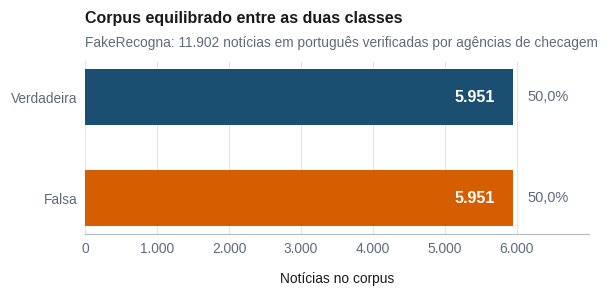

In [8]:
contagem = df['classe'].value_counts().reindex(['Verdadeira', 'Falsa'])
proporcao = contagem / contagem.sum()

fig, ax = plt.subplots(figsize=(LARGURA, 5.2 * CM))
barras = ax.barh(contagem.index, contagem.values,
                 color=[AZUL, LARANJA], height=0.56)

for b, n, p in zip(barras, contagem.values, proporcao.values):
    ax.annotate(mil(n),
                xy=(n, b.get_y() + b.get_height() / 2), xytext=(-12, 0),
                textcoords='offset points', ha='right', va='center',
                color='white', fontsize=T_TITULO, fontweight='bold')
    ax.annotate(pct(p, 1),
                xy=(n, b.get_y() + b.get_height() / 2), xytext=(9, 0),
                textcoords='offset points', ha='left', va='center',
                color=SUAVE, fontsize=T_ROTULO)

ax.invert_yaxis()
grade_x(ax)
eixo_milhar(ax, 'x')
ax.set_xlabel('Notícias no corpus')
folga(ax, 'x', 0.12)
titulo(ax, 'Corpus equilibrado entre as duas classes',
       'FakeRecogna: ' + mil(len(df)) + ' notícias em português verificadas '
       'por agências de checagem')
salvar(fig, 'fig_corpus_balanceamento')
plt.show()


## 6. Figura — completude dos campos

Esta é a figura que sustenta a decisão metodológica de descartar o subtítulo. Se um campo estiver preenchido em uma classe e vazio na outra, sua simples presença é um atalho preditivo: o modelo aprende a prática editorial de quem publicou, não o conteúdo da notícia.

           Verdadeira  Falsa  distancia
Categoria       100.0  100.0        0.0
Noticia         100.0  100.0        0.0
Classe          100.0  100.0        0.0
URL             100.0  100.0        0.0
Titulo          100.0   99.5        0.5
Subtitulo        18.5   75.3       56.8
[figura] fig_corpus_completude.png      15.0 x 9.6 cm  (margem branca completada)


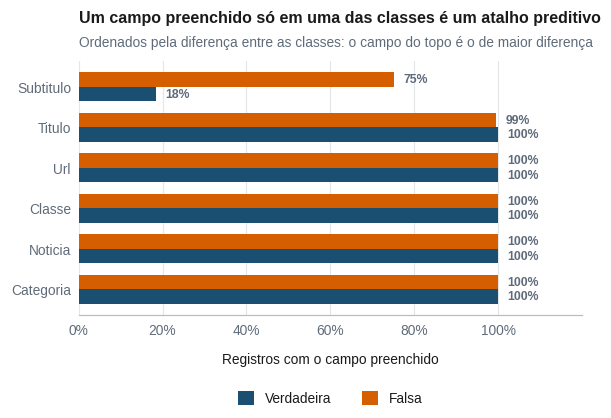

In [9]:
campos = [c for c in COL.values() if c is not None]

def preenchido(serie):
    s = serie.astype(str).str.strip()
    return 1 - ((serie.isna()) | (s == '') | (s.str.lower() == 'nan')).mean()

tabela = pd.DataFrame({
    cl: [preenchido(bruto.loc[df['classe'] == cl, c]) for c in campos]
    for cl in ['Verdadeira', 'Falsa']
}, index=campos)
tabela['distancia'] = (tabela['Verdadeira'] - tabela['Falsa']).abs()
tabela = tabela.sort_values('distancia')
print((tabela * 100).round(1))

fig, ax = plt.subplots(figsize=(LARGURA, 0.74 * CM * len(tabela) + 3.2 * CM))
y = np.arange(len(tabela))
alt = 0.36
b1 = ax.barh(y - alt / 2, tabela['Verdadeira'], alt, label='Verdadeira', color=AZUL)
b2 = ax.barh(y + alt / 2, tabela['Falsa'], alt, label='Falsa', color=LARANJA)
rotular_h(ax, b1, fmt='{:.0%}', tam=T_PEQUENO, cor=SUAVE)
rotular_h(ax, b2, fmt='{:.0%}', tam=T_PEQUENO, cor=SUAVE)

ax.set_yticks(y, [c.capitalize() for c in tabela.index])
ax.set_xlim(0, 1.20)
ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
eixo_percentual(ax, 'x')
grade_x(ax)
ax.set_xlabel('Registros com o campo preenchido')
# Legenda fora da área de plotagem: dentro dela encobre as barras de baixo.
legenda_abaixo(ax)
titulo(ax, 'Um campo preenchido só em uma das classes é um atalho preditivo',
       'Ordenados pela diferença entre as classes: o campo do topo é o de '
       'maior diferença')
salvar(fig, 'fig_corpus_completude')
plt.show()


## 7. Vazamento do veredito pelo título

Esta seção mede o vazamento que motivou a exclusão do título, e produz os números que o artigo reporta. O procedimento é simples: contar, em cada classe, quantos títulos trazem expressão com que a agência anuncia que a alegação é falsa, e verificar que acurácia uma regra baseada só nessa marca alcançaria.

A medição vale por si como resultado. Um corpus em que uma expressão regular acerta quatro em cada cinco registros não está medindo detecção de desinformação enquanto esse campo estiver na entrada — e isso vale para qualquer trabalho que use o FakeRecogna com o título.

In [10]:
# Expressões com que a agência anuncia o veredito no próprio título.
# Os grupos são não capturantes: com grupo de captura o pandas emite aviso.
MARCAS_VEREDITO = {
    '#boato': r'#\s*boato',
    '#fake': r'#\s*fake',
    'é fake': r'\bé\s+#?fake\b',
    'é falso / é falsa': r'\bé\s+fals[oa]\b',
    'é mentira': r'\bé\s+mentira\b',
    'boato (isolado)': r'\bboatos?\b',
    'fake news': r'\bfake\s+news\b',
    'não é verdade': r'\bnão\s+é\s+verdade\b',
    'enganoso': r'\bengano[sa]',
    'verificamos / desmentido': r'\b(?:verificamos|checamos|desmentid)',
}

titulos = bruto[COL['titulo']].fillna('').astype(str).str.lower()
e_falsa = (df['classe'] == 'Falsa').to_numpy()

linhas, tem_marca = [], np.zeros(len(titulos), dtype=bool)
for nome, padrao in MARCAS_VEREDITO.items():
    bate = titulos.str.contains(padrao, regex=True, na=False).to_numpy()
    tem_marca |= bate
    linhas.append({'marca': nome,
                   'em_falsas': float(bate[e_falsa].mean()),
                   'em_verdadeiras': float(bate[~e_falsa].mean())})

vazamento = pd.DataFrame(linhas)
vazamento['diferenca_pp'] = 100 * (vazamento['em_falsas']
                                   - vazamento['em_verdadeiras'])
vazamento = vazamento.sort_values('diferenca_pp', ascending=False)

prop_falsas = float(tem_marca[e_falsa].mean())
prop_verdadeiras = float(tem_marca[~e_falsa].mean())
# Acurácia de uma regra que não aprende nada: marca no título => falsa.
acerto_regra = float((tem_marca.astype(int) == df['rotulo'].to_numpy()).mean())

vazamento.loc[len(vazamento)] = {
    'marca': 'QUALQUER MARCA', 'em_falsas': prop_falsas,
    'em_verdadeiras': prop_verdadeiras,
    'diferenca_pp': 100 * (prop_falsas - prop_verdadeiras)}
vazamento.to_csv(DADOS / 'vazamento_titulo.csv', index=False)

print((vazamento.assign(em_falsas=lambda t: (100 * t['em_falsas']).round(1),
                        em_verdadeiras=lambda t: (100 * t['em_verdadeiras']).round(1),
                        diferenca_pp=lambda t: t['diferenca_pp'].round(1))
       ).to_string(index=False))
print('\nregra sem aprendizado ("marca no título -> falsa"):', pct(acerto_regra, 2))
print('texto de análise inclui o título?', INCLUIR_TITULO)


                   marca  em_falsas  em_verdadeiras  diferenca_pp
         boato (isolado)       41.9             0.0          41.9
                  #boato       41.7             0.0          41.7
                   #fake       19.6             0.0          19.6
                  é fake       16.8             0.0          16.8
       é falso / é falsa        2.6             0.1           2.5
                enganoso        1.0             0.0           1.0
               fake news        0.7             0.4           0.3
verificamos / desmentido        0.2             0.0           0.2
           não é verdade        0.1             0.0           0.1
               é mentira        0.1             0.0           0.1
          QUALQUER MARCA       66.1             0.5          65.6

regra sem aprendizado ("marca no título -> falsa"): 82,78%
texto de análise inclui o título? False


### Figura — prevalência das marcas de veredito

[figura] fig_vazamento_titulo.png       15.0 x 9.4 cm  (reduzida 9.8%)


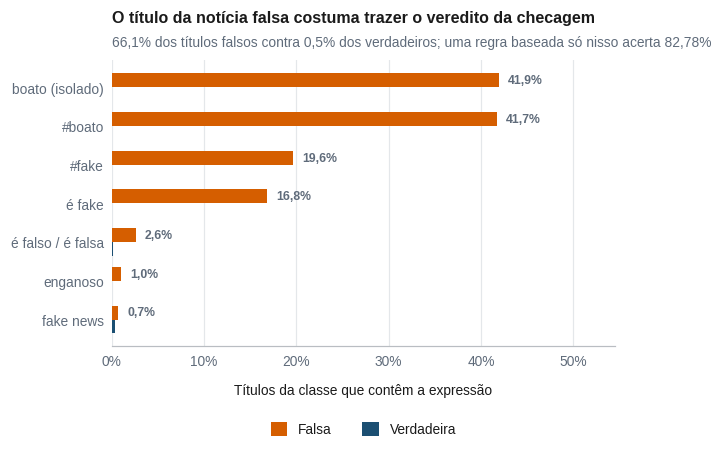

In [11]:
mostrar = vazamento[vazamento['marca'] != 'QUALQUER MARCA']
mostrar = mostrar[mostrar['em_falsas'] >= 0.005].sort_values('em_falsas')

fig, ax = plt.subplots(figsize=(LARGURA, 0.74 * CM * len(mostrar) + 3.4 * CM))
y = np.arange(len(mostrar))
alt = 0.36
b1 = ax.barh(y + alt / 2, mostrar['em_falsas'], alt, label='Falsa', color=LARANJA)
b2 = ax.barh(y - alt / 2, mostrar['em_verdadeiras'], alt, label='Verdadeira',
             color=AZUL)
rotular_h(ax, b1, fmt='{:.1%}', tam=T_PEQUENO, cor=SUAVE)

ax.set_yticks(y, mostrar['marca'])
ax.set_xlim(0, max(float(mostrar['em_falsas'].max()) * 1.30, 0.1))
eixo_percentual(ax, 'x')
grade_x(ax)
ax.set_xlabel('Títulos da classe que contêm a expressão')
legenda_abaixo(ax)
titulo(ax, 'O título da notícia falsa costuma trazer o veredito da checagem',
       '{} dos títulos falsos contra {} dos verdadeiros; uma regra baseada só '
       'nisso acerta {}'.format(pct(prop_falsas), pct(prop_verdadeiras),
                                pct(acerto_regra, 2)))
salvar(fig, 'fig_vazamento_titulo')
plt.show()


## 8. Duplicatas e republicações

Um corpus montado a partir de acervos de seis agências pode conter o mesmo boato desmentido por mais de uma delas, ou a mesma matéria republicada. Se um par desses cair com uma cópia no treino e outra no teste, o modelo não generaliza: ele reconhece um texto que já viu, e a acurácia reportada passa a incluir esse reconhecimento.

A verificação tem duas partes. Cópias exatas saem por comparação direta do texto normalizado. Quase-duplicatas — mesma notícia com edição leve — saem pela similaridade do cosseno sobre TF-IDF, tomando para cada registro o vizinho mais próximo. O que interessa não é o número de pares, mas quantos deles cruzam a fronteira entre treino e teste.

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

normalizado = (df['texto'].fillna('').astype(str)
               .str.lower().str.replace(r'\s+', ' ', regex=True).str.strip())

exatas = normalizado.duplicated(keep=False)
print('cópias exatas:', int(exatas.sum()), 'registros em',
      int(normalizado[exatas].nunique()), 'grupos')

vetor_dup = TfidfVectorizer(max_features=20000, min_df=2, strip_accents='unicode')
M = vetor_dup.fit_transform(normalizado)

# Vizinho mais proximo de cada registro, excluindo ele mesmo.
vizinhanca = NearestNeighbors(n_neighbors=2, metric='cosine').fit(M)
distancias, indices = vizinhanca.kneighbors(M)
similaridade = 1 - distancias[:, 1]
par = indices[:, 1]

particao = df['particao'].to_numpy()
rotulo = df['rotulo'].to_numpy()

print('\n{:<12} {:>9} {:>14} {:>16}'.format(
    'limiar', 'registros', 'cruzam part.', 'rótulo difere'))
linhas_dup = []
for limiar in (0.99, 0.95, 0.90, 0.80):
    acima = similaridade >= limiar
    cruza = acima & (particao != particao[par])
    difere = acima & (rotulo != rotulo[par])
    print('{:<12} {:>9} {:>14} {:>16}'.format(
        '>= ' + br('{:.2f}'.format(limiar)), int(acima.sum()),
        int(cruza.sum()), int(difere.sum())))
    linhas_dup.append({'limiar': limiar, 'registros': int(acima.sum()),
                       'cruzam_particao': int(cruza.sum()),
                       'rotulo_diferente': int(difere.sum())})

n_teste = int((particao == 'teste').sum())
for linha in linhas_dup:
    acima = similaridade >= linha['limiar']
    linha['teste_com_par_no_treino'] = int(
        (acima & (particao == 'teste') & (particao[par] == 'treino')).sum())
pd.DataFrame(linhas_dup).to_csv(DADOS / 'duplicatas.csv', index=False)

vazam = int(((similaridade >= 0.90) & (particao == 'teste')
             & (particao[par] == 'treino')).sum())
print('\nregistros do teste com quase-duplicata no treino (>= 0,90): {} de {} ({})'
      .format(vazam, n_teste, pct(vazam / n_teste, 2)))
if vazam / n_teste > 0.01:
    print('ATENÇÃO: acima de 1% do teste tem correspondente no treino. A '
          'acurácia reportada inclui reconhecimento de texto já visto e '
          'precisa ser qualificada no artigo.')
else:
    print('Abaixo de 1% do conjunto de teste — contaminação desprezível.')


cópias exatas: 32 registros em 16 grupos

limiar       registros   cruzam part.    rótulo difere
>= 0,99             49              6                0
>= 0,95            138             24                2
>= 0,90            223             55                8
>= 0,80            465            129               26

registros do teste com quase-duplicata no treino (>= 0,90): 29 de 2381 (1,22%)
ATENÇÃO: acima de 1% do teste tem correspondente no treino. A acurácia reportada inclui reconhecimento de texto já visto e precisa ser qualificada no artigo.


### Pares quase idênticos com rótulos opostos

Dois textos quase iguais, um rotulado falso e outro verdadeiro, merecem leitura humana: podem ser ruído de rotulagem, ou uma agência que reproduziu quase literalmente a matéria verdadeira para desmentir uma distorção dela. A célula imprime os pares para inspeção — não remove nada.

In [13]:
opostos = np.flatnonzero((similaridade >= 0.90) & (rotulo != rotulo[par]))
vistos = set()
print('{} registros com vizinho >= 0,90 de rótulo oposto\n'.format(len(opostos)))
for i in opostos:
    j = int(par[i])
    chave = tuple(sorted((int(i), j)))
    if chave in vistos:
        continue
    vistos.add(chave)
    print('similaridade {}'.format(br('{:.3f}'.format(similaridade[i]))))
    for k in chave:
        print('  [{}] {:<10} {}'.format(df['particao'].iloc[k], df['classe'].iloc[k],
                                        ' '.join(str(df['texto'].iloc[k]).split())[:150]))
    print()


8 registros com vizinho >= 0,90 de rótulo oposto

similaridade 0,925
  [treino] Verdadeira vídeo viral facebook mostrar cabo eleitoral prefeito eleito fortalezar josé sarto pdt transportar urna eletrônica adulterar carro particular verdade o
  [treino] Falsa      vídeo viral facebook mostrar cabo eleitoral prefeito eleito fortalezar josé sarto pdt transportar urna eletrônica adulterar carro particular verdade o

similaridade 0,946
  [treino] Verdadeira vídeo compartilhar rede social homem apresentar funcionário governar o cemitério vila formoso cova aberto realizar sepultamento pandemia coronavírus a
  [treino] Falsa      vídeo compartilhar rede social homem apresentar funcionário governar o cemitério vila formoso cova aberto realizar sepultamento pandemia coronavírus a

similaridade 0,906
  [treino] Verdadeira publicação feito twitter arthur weintraub assessor especial presidente jair bolsonaro e irmão ex-ministro educação abraham weintraub informação desatu
  [treino] Falsa      publ

## 9. Figura — similaridade com o vizinho mais próximo

[figura] fig_duplicatas.png             15.0 x 6.8 cm  (reduzida 9.7%)


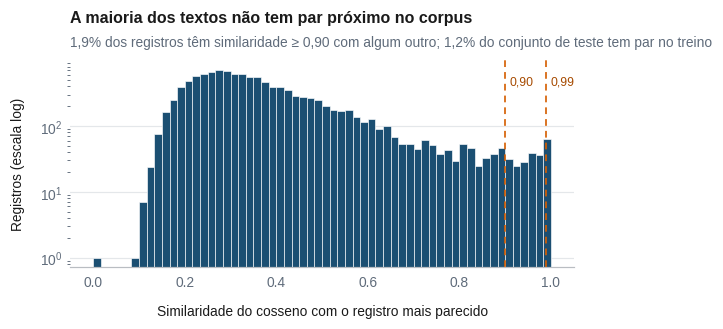

In [14]:
fig, ax = plt.subplots(figsize=(LARGURA, 6.2 * CM))
ax.hist(similaridade, bins=60, color=AZUL, edgecolor='white', linewidth=0.4)
ax.set_yscale('log')
for limiar, rotulo_lim in ((0.90, '0,90'), (0.99, '0,99')):
    ax.axvline(limiar, color=LARANJA, linestyle=(0, (4, 3)), linewidth=1.1)
    ax.annotate(rotulo_lim, xy=(limiar, 1), xycoords=('data', 'axes fraction'),
                xytext=(3, -10), textcoords='offset points',
                ha='left', va='top', fontsize=T_PEQUENO, color=LARANJA_TEXTO)
grade_y(ax)
ax.set_xlabel('Similaridade do cosseno com o registro mais parecido')
ax.set_ylabel('Registros (escala log)')

# O título sai do dado. Cravar a conclusão no código faz a figura afirmar o
# mesmo seja qual for o corpus — e mentir quando o corpus muda.
prox = float((similaridade >= 0.90).mean())
titulo(ax, ('A maioria dos textos não tem par próximo no corpus'
            if prox < 0.10 else
            'Boa parte do corpus tem um texto quase idêntico em outro registro'),
       '{} dos registros têm similaridade ≥ 0,90 com algum outro; {} do '
       'conjunto de teste tem par no treino'
       .format(pct(prox, 1), pct(vazam / n_teste, 1)))
salvar(fig, 'fig_duplicatas')
plt.show()


## 10. Figura — comprimento dos textos

Dois painéis sobre a mesma variável. O histograma mostra a forma das distribuições e o box plot resume posição e dispersão: notícias falsas são sistematicamente mais curtas, e essa diferença volta a aparecer na Fase 7 como confundidor do experimento de robustez.

[figura] fig_corpus_tamanho.png         15.0 x 8.7 cm  (margem branca completada)


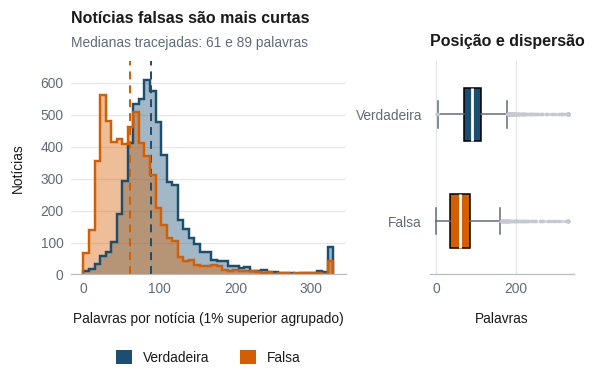

In [15]:
corte = df['n_palavras'].quantile(0.99)
fig, eixos = plt.subplots(1, 2, figsize=(LARGURA, 6.4 * CM),
                          gridspec_kw={'width_ratios': [1.9, 1], 'wspace': 0.40})

ax = eixos[0]
faixas = np.linspace(0, corte, 46)

# Nada de texto dentro da área de dados: com o corpus real os dois picos
# ficam colados e qualquer rótulo sobre eles vira borrão. Os nomes das
# classes vão para a legenda abaixo do eixo e as medianas para a linha de
# apoio do título, que é espaço vazio de sobra.
medianas = {}
for cl, cor in [('Verdadeira', AZUL), ('Falsa', LARANJA)]:
    sub = df.loc[df['classe'] == cl, 'n_palavras'].clip(upper=corte)
    medianas[cl] = df.loc[df['classe'] == cl, 'n_palavras'].median()
    ax.hist(sub, bins=faixas, color=cor, alpha=0.40)
    ax.hist(sub, bins=faixas, histtype='step', color=cor, linewidth=1.6)
    ax.axvline(medianas[cl], color=cor, linestyle=(0, (4, 3)), linewidth=1.3)

grade_y(ax)
eixo_milhar(ax, 'y')
ax.margins(y=0.10)
ax.set_xlabel('Palavras por notícia (1% superior agrupado)')
ax.set_ylabel('Notícias')
legenda_manual(ax, [('Verdadeira', AZUL), ('Falsa', LARANJA)])
titulo(ax, 'Notícias falsas são mais curtas',
       'Medianas tracejadas: {} e {} palavras'
       .format(mil(medianas['Falsa']), mil(medianas['Verdadeira'])))

ax = eixos[1]
dados = [df.loc[df['classe'] == cl, 'n_palavras'].clip(upper=corte)
         for cl in ['Verdadeira', 'Falsa']]
bp = ax.boxplot(dados, vert=False, widths=0.5, patch_artist=True,
                medianprops=dict(color='white', linewidth=1.8),
                flierprops=dict(marker='o', markersize=2.2,
                                markerfacecolor=NEUTRO,
                                markeredgecolor='none', alpha=0.5),
                whiskerprops=dict(color=SUAVE), capprops=dict(color=SUAVE))
for caixa, cor in zip(bp['boxes'], [AZUL, LARANJA]):
    caixa.set_facecolor(cor)
ax.set_yticks([1, 2], ['Verdadeira', 'Falsa'])
ax.invert_yaxis()
grade_x(ax)
ax.set_xlabel('Palavras')
titulo(ax, 'Posição e dispersão')

salvar(fig, 'fig_corpus_tamanho')
plt.show()


## 11. Síntese numérica

Os valores gravados aqui alimentam a Seção 3.1 do artigo e são lidos pelas fases seguintes, para que nenhum número apareça digitado à mão em mais de um lugar.

In [16]:
resumo = (df.groupby('classe')
            .agg(notícias=('texto', 'size'),
                 palavras_média=('n_palavras', 'mean'),
                 palavras_mediana=('n_palavras', 'median'),
                 caracteres_média=('n_chars', 'mean'))
            .round(1))
resumo.loc['Total'] = [len(df), df['n_palavras'].mean(),
                       df['n_palavras'].median(), df['n_chars'].mean()]
resumo = resumo.round(1)
resumo.to_csv(DADOS / 'metricas_corpus.csv')
print(resumo.to_string())
print('\nFiguras nesta fase:', sorted(p.name for p in FIGURAS.glob('fig_corpus_*')))


            notícias  palavras_média  palavras_mediana  caracteres_média
classe                                                                  
Falsa         5951.0            68.6              61.0             460.3
Verdadeira    5951.0           101.9              89.0             709.2
Total        11902.0            85.2              77.0             584.8

Figuras nesta fase: ['fig_corpus_balanceamento.png', 'fig_corpus_completude.png', 'fig_corpus_tamanho.png', 'fig_corpus_temporal.png', 'fig_corpus_termos.png']
